In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [2]:
#datast: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database

In [3]:
df = pd.read_csv('../data/16-diabetes.csv')

In [4]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


### Dataset Description

The dataset contains medical measurements and diagnostic information used to predict diabetes outcomes.

It consists of **8 input features** and **1 target variable**.

#### Feature Descriptions

| Feature | Description |
|---|---|
| **Pregnancies** | Number of times the patient has been pregnant. |
| **Glucose** | Plasma glucose concentration measured two hours after an oral glucose tolerance test. |
| **BloodPressure** | Diastolic blood pressure measured in mmHg. |
| **SkinThickness** | Triceps skinfold thickness measured in millimeters (mm). Used as an indicator of body fat. |
| **Insulin** | Two-hour serum insulin level measured in µU/mL. |
| **BMI** | Body Mass Index, calculated using weight and height. |
| **DiabetesPedigreeFunction** | A numerical score representing genetic predisposition to diabetes based on family history. |
| **Age** | Age of the patient in years. |
| **Outcome** | Target variable indicating diabetes status: 0 = Negative, 1 = Positive. |

#### Additional Information

- The dataset contains medical records of Pima Indian women aged 21 years and older.
- All features are numerical.
- `Outcome` is the target variable, making this a **binary classification problem**.
- Some medical measurements may contain zero values that represent missing or invalid data. These will be investigated during the data quality analysis.


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [6]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [7]:
(df.eq(0).sum() / len(df)) * 100

Pregnancies                 14.453125
Glucose                      0.651042
BloodPressure                4.557292
SkinThickness               29.557292
Insulin                     48.697917
BMI                          1.432292
DiabetesPedigreeFunction     0.000000
Age                          0.000000
Outcome                     65.104167
dtype: float64

### Descriptive Statistics and Data Quality Assessment

#### Descriptive Statistics

Descriptive statistics were examined using `df.describe()` to understand the distributions and general characteristics of the numerical features.

The analysis includes the mean, standard deviation, minimum and maximum values, and quartiles. These statistics help identify unusual values, potential outliers, and differences in feature scales.

#### Data Quality Assessment

The dataset contains **768 observations and 9 columns**. According to `df.info()`, all columns have numerical data types and contain 768 non-null values.

However, the absence of null values does not necessarily indicate that the dataset is free of missing or invalid measurements. Some medical features may contain zero values representing unavailable measurements.

To investigate this issue, the percentage of zero values was calculated for each column.

#### Zero Value Analysis

| Feature | Zero Count | Zero Percentage |
|---|---:|---:|
| Pregnancies | 111 | 14.45% |
| Glucose | 5 | 0.65% |
| BloodPressure | 35 | 4.56% |
| SkinThickness | 227 | 29.56% |
| Insulin | 374 | 48.70% |
| BMI | 11 | 1.43% |
| DiabetesPedigreeFunction | 0 | 0.00% |
| Age | 0 | 0.00% |
| Outcome | 500 | 65.10% |

#### Key Findings

- **Pregnancies:** Zero values are valid because a patient may have had no previous pregnancies.
- **Glucose, BloodPressure, and BMI:** Zero values are not physiologically plausible measurements and may represent missing data.
- **SkinThickness:** Approximately 29.56% of the values are zero, suggesting a substantial number of missing measurements.
- **Insulin:** Approximately 48.70% of the values are zero, making it the feature with the highest proportion of potentially missing measurements.
- **Age and DiabetesPedigreeFunction:** Neither feature contains zero values.
- **Outcome:** Approximately 65.10% of the observations belong to class 0, while 34.90% belong to class 1. These values represent valid class labels rather than missing data.

#### Conclusion

The initial data quality analysis identified potentially missing measurements encoded as zeros, especially in the `Insulin` and `SkinThickness` features.

These findings indicate that data preprocessing will be necessary before model training. However, no values have been modified or removed at this stage.

Appropriate strategies for handling missing values will be evaluated after further exploratory analysis, with particular attention to preventing data leakage.

### Distribution Analysis

#### 1.4.1 Insulin Distribution

The distribution of insulin levels is examined to identify potential data quality issues, skewness, and unusual values.


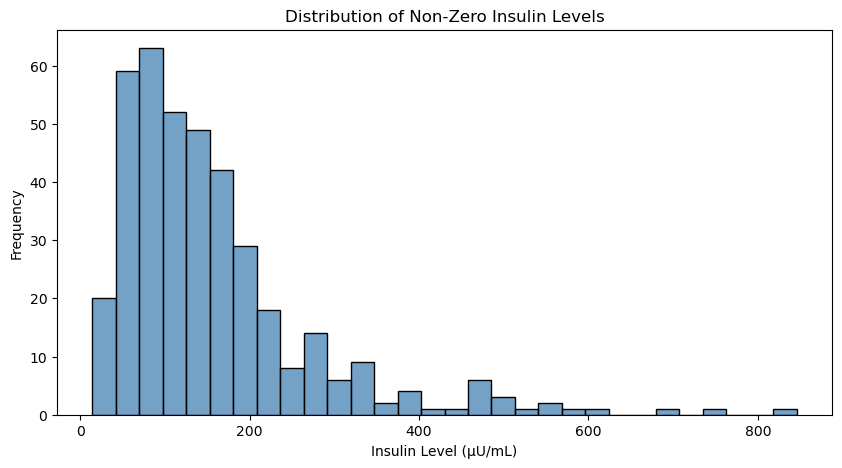

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Insulin"] > 0],
    x="Insulin",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Non-Zero Insulin Levels")
plt.xlabel("Insulin Level (µU/mL)")
plt.ylabel("Frequency")

plt.show()


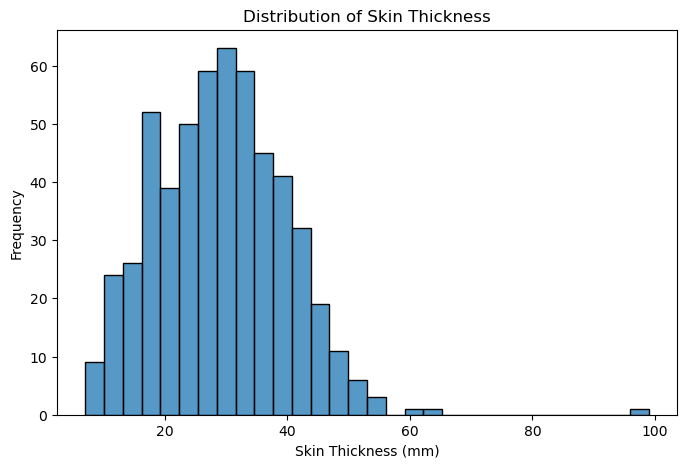

In [9]:
plt.figure(figsize=(8,5))
sns.histplot(
    data = df[df['SkinThickness'] > 0],
    x = 'SkinThickness',
    bins = 30,
    kde = False
)
plt.title("Distribution of Skin Thickness")
plt.xlabel("Skin Thickness (mm)")
plt.ylabel("Frequency")
plt.show()

### Boxplot Analysis

#### 1.5.1 Insulin Outlier Analysis

A boxplot is used to examine the spread of non-zero insulin measurements, identify the median and quartiles, and detect potential outliers using the IQR method.


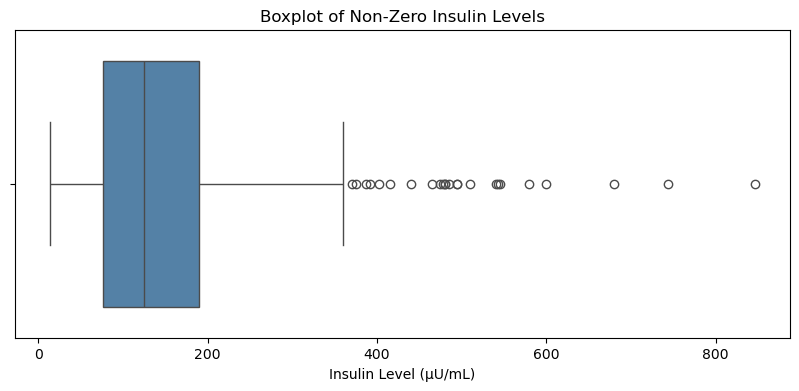

In [10]:
plt.figure(figsize=(10,4))
sns.boxplot(
    data = df[df['Insulin'] > 0],
    x = 'Insulin',
    color = 'steelblue',
    whis=1.5,
    showfliers=True
)
plt.title("Boxplot of Non-Zero Insulin Levels")
plt.xlabel("Insulin Level (µU/mL)")
plt.show()

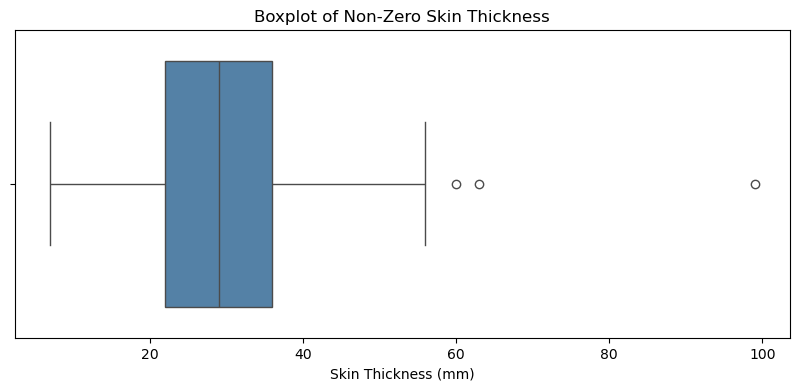

In [11]:
plt.figure(figsize=(10,4))
sns.boxplot(
    data = df[df['SkinThickness'] > 0],
    x = 'SkinThickness',
    color = 'steelblue',
    whis=1.5,
    showfliers=True
)
plt.title("Boxplot of Non-Zero Skin Thickness")
plt.xlabel("Skin Thickness (mm)")
plt.show()

#### IQR-Based Outlier Detection

The Interquartile Range (IQR) method is used to identify potential outliers in the non-zero measurements.

The IQR is calculated as the difference between the third quartile (Q3) and the first quartile (Q1).

- Lower Bound = Q1 - 1.5 × IQR
- Upper Bound = Q3 + 1.5 × IQR

Observations outside these boundaries are considered potential outliers. They are not automatically treated as incorrect measurements.


In [12]:
insulin_values = df.loc[df['Insulin'] > 0,'Insulin']

Q1 = insulin_values.quantile(0.25)
Q3 = insulin_values.quantile(0.75)
IQR = Q3 - Q1

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

Q1: 76.25
Q3: 190.0
IQR: 113.75


In [13]:
lower_bound = Q1 - (1.5 * IQR)
upper_bound = Q3 + (1.5 * IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Lower Bound: -94.375
Upper Bound: 360.625


In [14]:
insulin_outliers = insulin_values[
    (insulin_values < lower_bound) |
    (insulin_values > upper_bound)
]

print("Number of potential outliers:", len(insulin_outliers))

Number of potential outliers: 24


In [15]:
skinthickness_values = df.loc[df['SkinThickness'] > 0, 'SkinThickness']
Q1_skin = skinthickness_values.quantile(0.25)
Q3_skin = skinthickness_values.quantile(0.75)
IQR_skin = Q3_skin - Q1_skin
print(f'SkinThicknessQ3:{Q3_skin}')
print(f'SkinThicknessQ1:{Q1_skin}')
print(f'SkinThicknessIQR:{IQR_skin}')

SkinThicknessQ3:36.0
SkinThicknessQ1:22.0
SkinThicknessIQR:14.0


In [16]:
lower_bound_skin = Q1_skin - (1.5 * IQR_skin)
upper_bound_skin = Q3_skin + (1.5 * IQR_skin)
print("Lower Bound:", lower_bound_skin)
print("Upper Bound:", upper_bound_skin)

Lower Bound: 1.0
Upper Bound: 57.0


In [17]:
skinthickness_values = skinthickness_values[
    (skinthickness_values < lower_bound_skin) |
    (skinthickness_values > upper_bound_skin)
]

print("Number of potential outliers:", len(skinthickness_values))

Number of potential outliers: 3


#### Outlier Analysis Results

The IQR method was applied to non-zero Insulin and SkinThickness measurements to identify potential outliers.

| Feature | Lower Bound | Upper Bound | Outlier Count | Outlier Percentage |
|---|---:|---:|---:|---:|
| Insulin | -94.375 | 360.625 | 24 | 6.09% |
| SkinThickness | 1.0 | 57.0 | 3 | 0.55% |

**Key Findings:**

- **Insulin:** Approximately 6.09% of non-zero insulin measurements were identified as potential outliers. The distribution shows a noticeable right skew.
- **SkinThickness:** Only 0.55% of non-zero measurements were identified as potential outliers. Most observations are concentrated around the central values.

**Conclusion:**

The IQR analysis identified potential outliers in both features, particularly in Insulin. However, these observations are not necessarily incorrect measurements.

No outliers were removed at this stage. Further evaluation is required before deciding whether any outlier treatment is necessary.


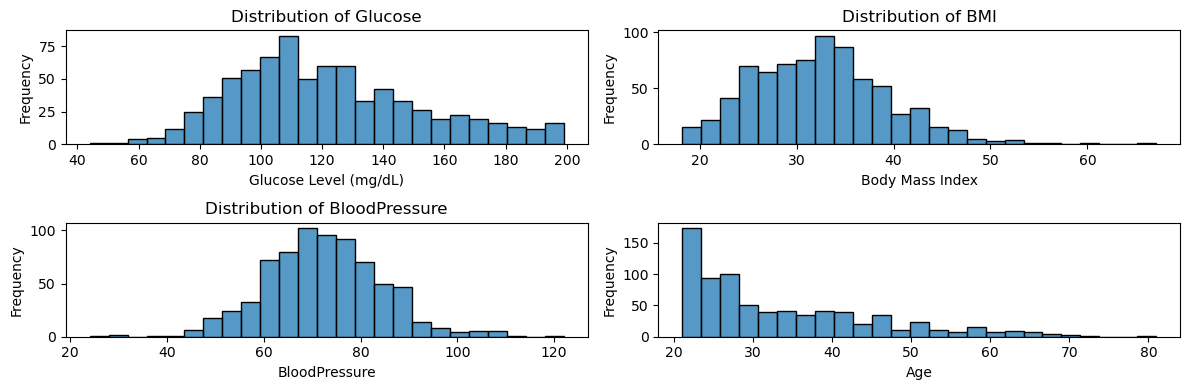

In [18]:
fig,axes = plt.subplots(2,2,figsize=(12,4))

sns.histplot(data=df[df["Glucose"] > 0],x='Glucose',bins=25,ax=axes[0,0])
axes[0,0].set_title("Distribution of Glucose")
axes[0,0].set_xlabel("Glucose Level (mg/dL)")
axes[0,0].set_ylabel("Frequency")

sns.histplot(data=df[df["BMI"] > 0],x='BMI',bins=25,ax=axes[0,1])
axes[0,1].set_title('Distribution of BMI')
axes[0,1].set_xlabel('Body Mass Index')
axes[0,1].set_ylabel('Frequency')

sns.histplot(data=df[df["BloodPressure"] > 0],x='BloodPressure',bins=25,ax=axes[1,0])
axes[1,0].set_title('Distribution of BloodPressure')
axes[1,0].set_xlabel('BloodPressure')
axes[1,0].set_ylabel('Frequency')

sns.histplot(df,x='Age',bins=25,ax=axes[1,1])
axes[1,1].set_title('')
axes[1,1].set_xlabel('Age')
axes[1,1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

#### Distribution Analysis Findings

- **Glucose:** Most observations are concentrated between approximately 75 and 150 mg/dL. The distribution shows a slightly longer right tail.
- **BMI:** Most values are concentrated between approximately 25 and 40. The distribution is relatively bell-shaped, with some higher values extending the right tail.
- **BloodPressure:** Most measurements are concentrated between approximately 60 and 90 mmHg, with the highest frequency around 70–80 mmHg.
- **Age:** The distribution is right-skewed, with a higher concentration of younger individuals. The number of observations generally decreases with increasing age.

**Data Quality Note:** Zero values are present in Glucose, BMI, and BloodPressure. These values require further investigation and will be addressed during preprocessing.


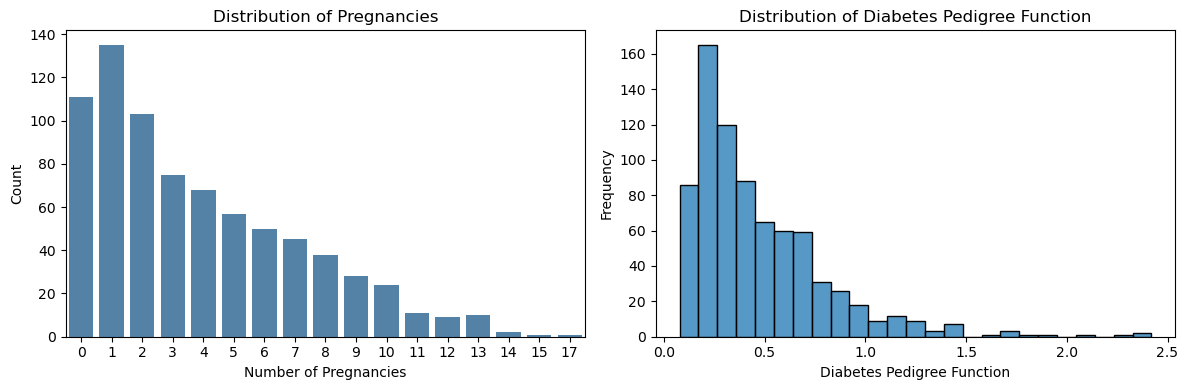

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(
    data=df,
    x="Pregnancies",
    order=sorted(df["Pregnancies"].unique()),
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Distribution of Pregnancies")
axes[0].set_xlabel("Number of Pregnancies")
axes[0].set_ylabel("Count")

sns.histplot(
    data=df,
    x='DiabetesPedigreeFunction',
    bins=25,
    ax=axes[1]
)

axes[1].set_title('Distribution of Diabetes Pedigree Function')
axes[1].set_xlabel('Diabetes Pedigree Function')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()


#### Distribution Analysis Findings

**Pregnancies**
- The most frequent number of pregnancies is 1.
- The number of observations generally decreases as the number of pregnancies increases.
- A countplot was preferred because Pregnancies is a discrete numerical feature.

**DiabetesPedigreeFunction**
- Most observations are concentrated at relatively low values, mainly between 0.1 and 0.8.
- The distribution is positively skewed (right-skewed).
- A small number of observations have relatively high values, suggesting potential outliers.

**Conclusion**

Both features show right-skewed distributions. However, their characteristics differ: Pregnancies represents discrete counts, while DiabetesPedigreeFunction contains continuous numerical scores.

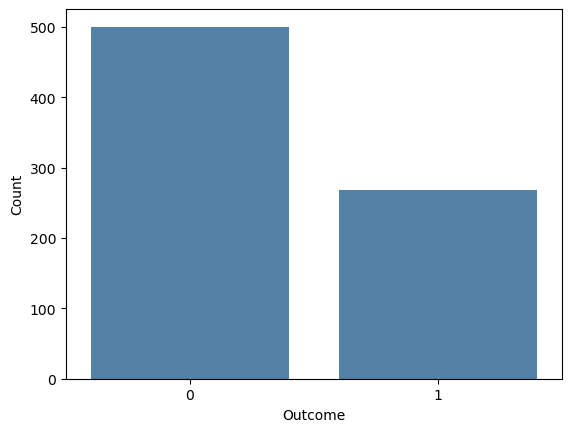

In [20]:
sns.countplot(
    data=df,
    x="Outcome",
    color="steelblue",
)
plt.xlabel('Outcome')
plt.ylabel('Count')
plt.show()

In [21]:
df['Outcome'].value_counts(normalize=True)

Outcome
0    0.651042
1    0.348958
Name: proportion, dtype: float64

### Target Variable Analysis

The distribution of the target variable (`Outcome`) was examined using a countplot and frequency analysis.

| Outcome | Count | Percentage |
|---|---:|---:|
| 0 (Negative) | 500 | 65.10% |
| 1 (Positive) | 268 | 34.90% |

#### Key Findings

- The dataset contains more negative cases than positive cases.
- The target variable shows a moderate class imbalance.
- Accuracy alone may be misleading when evaluating classification performance.
- Recall is particularly important for identifying positive diabetes cases and reducing false negatives.
- Precision, F1-score, and the confusion matrix will also be considered during model evaluation.

#### Conclusion

The observed class imbalance should be considered during model training and evaluation. A stratified train-test split will be used to preserve the class proportions in both datasets.

### Bivariate Analysis
#### Glucose vs. Outcome

This analysis examines the relationship between glucose levels and diabetes outcomes.

A boxplot is used to compare the distribution, median, and variability of glucose measurements between the two target classes.

Zero glucose measurements are excluded from this visualization because they are not considered valid measurements.

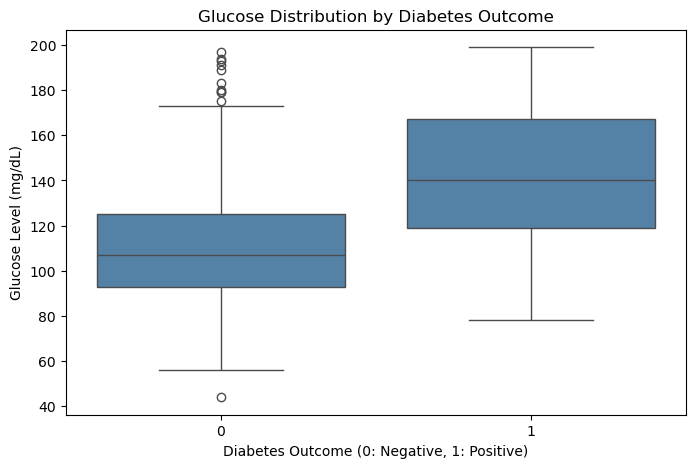

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df[df["Glucose"] > 0],
    x="Outcome",
    y="Glucose",
    color="steelblue"
)

plt.title("Glucose Distribution by Diabetes Outcome")
plt.xlabel("Diabetes Outcome (0: Negative, 1: Positive)")
plt.ylabel("Glucose Level (mg/dL)")

plt.show()

In [23]:
df[df["Glucose"] > 0].groupby("Outcome")["Glucose"].median()

Outcome
0    107.0
1    140.0
Name: Glucose, dtype: float64

#### Glucose vs. Outcome — Findings

- The median glucose level is higher in the diabetes-positive group (Outcome = 1).
- The positive group has a larger IQR, indicating greater variability within the middle 50% of its measurements.
- Several potential outliers are observed in the negative group.
- The glucose distributions of the two classes overlap considerably.

**Conclusion:**

Glucose appears to be a potentially useful feature for diabetes classification. However, the overlap between the two groups indicates that glucose alone may not be sufficient for accurate classification.

Other features should also be considered during model training.

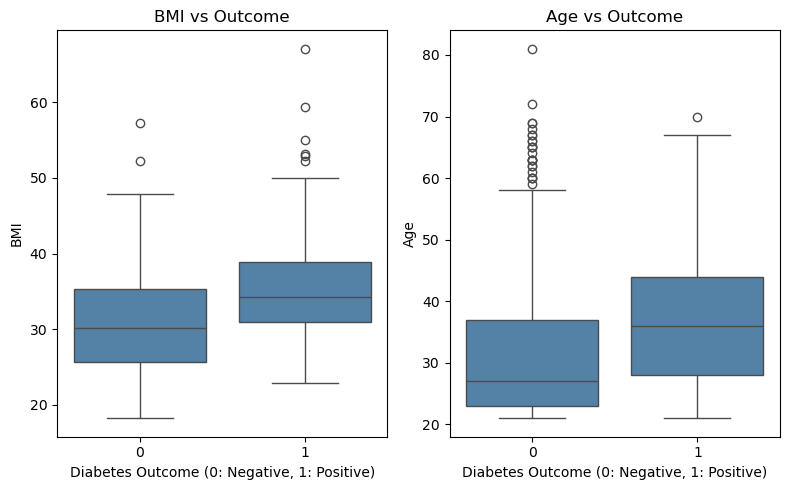

In [24]:
fig,axes= plt.subplots(1,2,figsize=(8,5))

sns.boxplot(
    data = df[df['BMI'] > 0],
    x='Outcome',
    y='BMI',
    color='steelblue',
    ax=axes[0]
)
axes[0].set_title('BMI vs Outcome')
axes[0].set_xlabel('Diabetes Outcome (0: Negative, 1: Positive)')
axes[0].set_ylabel('BMI')

sns.boxplot(
    data=df,
    x='Outcome',
    y='Age',
    color='steelblue',
    ax=axes[1]
)
axes[1].set_title('Age vs Outcome')
axes[1].set_xlabel('Diabetes Outcome (0: Negative, 1: Positive)')
axes[1].set_ylabel('Age')

plt.tight_layout()
plt.show()

In [25]:
df[df["BMI"] > 0].groupby("Outcome")["BMI"].agg(
    ["mean", "median", "std"]
)

,mean,median,std
Outcome,,,
0,30.859674,30.1,6.560737
1,35.406767,34.3,6.614982


#### 1.8.2 BMI and Age vs. Outcome

Boxplots were used to compare BMI and Age distributions across the two diabetes outcome classes.

**BMI Findings:**

- The diabetes-positive group has a higher median BMI than the negative group.
- The BMI distributions overlap considerably.
- Potential outliers are observed in both groups.
- BMI may be a useful predictor, but it does not clearly separate the two classes on its own.

**Age Findings:**

- The diabetes-positive group has a higher median age.
- The negative group shows a right-skewed distribution with several potential outliers.
- The positive group has a more balanced central distribution.
- Age may provide useful information for diabetes classification.

**Conclusion:**

Both BMI and Age show differences between the two outcome classes. However, substantial overlap remains.

These findings suggest potential predictive relationships rather than proving causation.

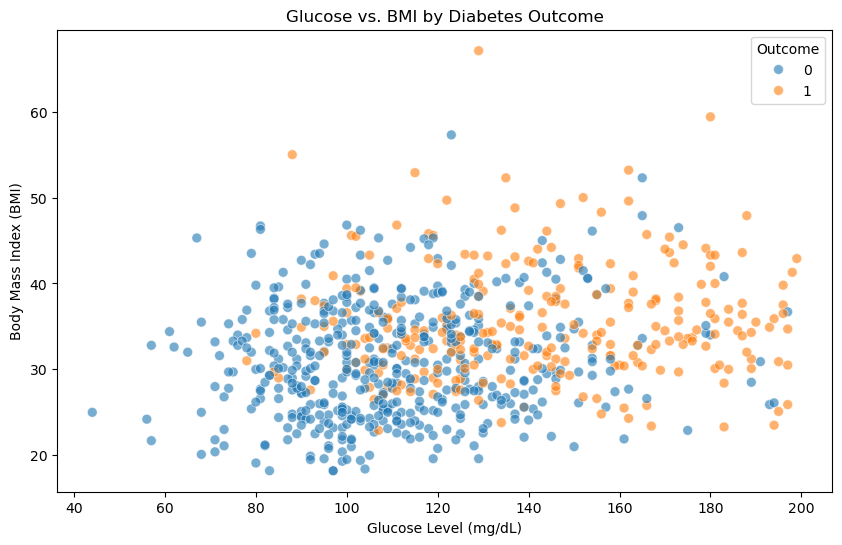

In [26]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df[(df["Glucose"] > 0) & (df["BMI"] > 0)],
    x="Glucose",
    y="BMI",
    hue="Outcome",
    alpha=0.6,
    s=50
)

plt.title("Glucose vs. BMI by Diabetes Outcome")
plt.xlabel("Glucose Level (mg/dL)")
plt.ylabel("Body Mass Index (BMI)")

plt.show()

In [27]:
high_glucose = df[df["Glucose"] > 160]
high_glucose["Outcome"].value_counts(normalize=True) * 100

Outcome
1    82.178218
0    17.821782
Name: proportion, dtype: float64

#### Scatterplot Analysis Findings

- The scatterplot does not show a strong apparent linear relationship between Glucose and BMI.
- The two outcome classes overlap considerably, particularly at moderate glucose levels.
- At higher glucose levels, especially above approximately 160 mg/dL, positive outcomes appear more frequent.
- However, the classes are not completely separated, indicating that Glucose and BMI alone may not be sufficient for accurate classification.

**Conclusion:**

Glucose and BMI may provide useful information for predicting diabetes outcomes. However, the considerable overlap between the two classes highlights the importance of considering additional features.

The relationship between numerical features will be further investigated using correlation analysis.

In [28]:
valid_data = df[
    (df["Glucose"] > 0) &
    (df["BMI"] > 0)
][["Glucose", "BMI"]]

valid_data.corr(method='pearson')

,Glucose,BMI
Glucose,1.000000,0.232771
BMI,0.232771,1.000000


In [29]:
eda_df = df.copy()

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

eda_df[zero_columns] = eda_df[zero_columns].replace(0, np.nan)

In [30]:
corr_matrix = eda_df.corr(method='pearson')

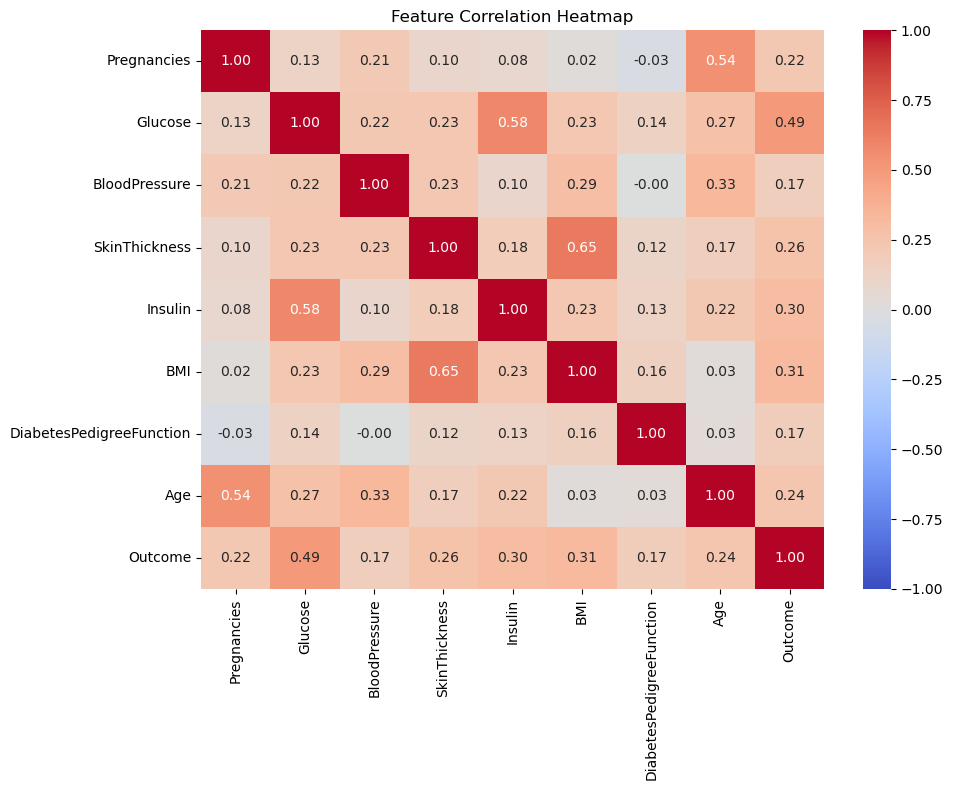

In [31]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    data = corr_matrix,
    annot=True,
    fmt= '.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

### EDA Summary

The exploratory data analysis revealed several important findings:

- The dataset contains 768 observations and 8 input features.
- Several medical features contain zero values that may represent missing measurements.
- Insulin and SkinThickness have particularly high proportions of potentially missing values.
- Potential outliers were identified, but no observations were removed.
- The target variable shows a moderate class imbalance.
- Glucose has the strongest positive correlation with Outcome among the examined features.
- Several features show overlapping distributions between the two target classes.

These findings will guide the preprocessing and model training stages.

## Model Development

### Train-Test Split

The dataset is divided into training and testing sets.

An 80/20 split is used, with stratification to preserve the original class distribution.

The test set will be kept separate from preprocessing decisions, model selection, and hyperparameter tuning to obtain a more reliable final evaluation.

In [32]:
X = df.drop('Outcome',axis=1)
y = df['Outcome']

In [33]:
from sklearn.model_selection import train_test_split

In [35]:
X_train,X_test,y_train,y_test = train_test_split(X,y,random_state=42,test_size=0.20,stratify=y)
print("X_train:", X_train.shape[0])
print("X_test:", X_test.shape[0])
print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))

X_train: 614
X_test: 154
Outcome
0    0.651466
1    0.348534
Name: proportion, dtype: float64
Outcome
0    0.649351
1    0.350649
Name: proportion, dtype: float64


### Data Preprocessing

#### Missing Value Handling

Some medical features contain zero values that represent potentially missing or invalid measurements.

These values are converted to NaN before applying a missing value imputation strategy.

Median imputation will be used as an initial approach because several features exhibit skewed distributions and potential outliers.

Imputation statistics will be learned only from the training data to prevent data leakage.

In [36]:
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()

zero_columns = [
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI"
]

X_train_clean[zero_columns] = X_train_clean[zero_columns].replace(0, np.nan)
X_test_clean[zero_columns] = X_test_clean[zero_columns].replace(0, np.nan)

In [38]:
(X_train_clean.isna().mean() * 100).round(2)

Pregnancies                  0.00
Glucose                      0.65
BloodPressure                3.75
SkinThickness               28.50
Insulin                     47.23
BMI                          1.47
DiabetesPedigreeFunction     0.00
Age                          0.00
dtype: float64

In [39]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy='median')

In [40]:
X_train_imputed = imputer.fit_transform(X_train_clean)
X_test_imputed = imputer.transform(X_test_clean)

X_train_imputed = pd.DataFrame(
    data= X_train_imputed,
    columns= X_train_clean.columns,
    index= X_train_clean.index,
)

X_test_imputed = pd.DataFrame(
    data = X_test_imputed,
    columns= X_test_clean.columns,
    index= X_test_clean.index
)

In [41]:
print("Training missing values:")
print(X_train_imputed.isna().sum())

print("\nTesting missing values:")
print(X_test_imputed.isna().sum())

Training missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64

Testing missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
dtype: int64


#### Median Imputation with SimpleImputer

Missing values are handled using Scikit-learn's `SimpleImputer` with the median strategy.

Median imputation was selected as an initial approach because several numerical features contain skewed distributions and potential outliers.

The imputer is fitted exclusively on the training data. The learned median values are then applied to both the training and test sets.

This approach prevents information from the test set from influencing the imputation process.

The effectiveness of this strategy will be evaluated during model training and validation.

In [43]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [44]:
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

In [45]:
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_imputed.columns,
    index=X_train_imputed.index
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_imputed.columns,
    index=X_test_imputed.index
)

#### Feature Scaling with StandardScaler

Feature scaling is applied using Scikit-learn's `StandardScaler`.

The scaler is fitted exclusively on the training data. The same scaling parameters are then applied to the test data to prevent data leakage.

After scaling, the training features have approximately zero mean and unit variance.

Scaling is particularly important for algorithms such as Logistic Regression and Support Vector Machines (SVM).

### Baseline Model: Logistic Regression

Logistic Regression is selected as the first baseline classification algorithm.

A Scikit-learn Pipeline is used to combine the following steps:

1. **SimpleImputer:** Replace missing values using the median strategy.
2. **StandardScaler:** Standardize numerical features.
3. **LogisticRegression:** Train a binary classification model.

The baseline model is trained using the original training features after invalid zero measurements have been marked as NaN.

No class weighting, hyperparameter tuning, or outlier treatment is applied at this stage.

Model performance will be evaluated using stratified cross-validation before the final test evaluation.

In [47]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [49]:
log_reg_pipline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ('model',LogisticRegression(max_iter=1000,random_state=42))
])

In [50]:
log_reg_pipline.fit(X_train_clean,y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=1000, random_state=42))])

In [54]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

In [55]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

In [57]:
cv_results = cross_validate(
    estimator=log_reg_pipline,
    X=X_train_clean,
    y=y_train,
    cv=cv,
    scoring=scoring
)
cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [58]:
cv_df = pd.DataFrame(cv_results)
cv_df.filter(like="test_")

,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,0.788618,0.793103,0.534884,0.638889,0.866860
1,0.788618,0.742857,0.604651,0.666667,0.839535
2,0.821138,0.862069,0.581395,0.694444,0.851163
3,0.780488,0.735294,0.581395,0.649351,0.848547
4,0.762295,0.685714,0.571429,0.623377,0.810714


In [59]:
cv_summary = cv_df.filter(like="test_").agg(
    ["mean", "std"]
).T

print(cv_summary.round(3))

                 mean    std
test_accuracy   0.788  0.021
test_precision  0.764  0.067
test_recall     0.575  0.025
test_f1         0.655  0.027
test_roc_auc    0.843  0.021


### Model Evaluation Using Cross-Validation

Stratified 5-Fold Cross-Validation is used to evaluate the baseline Logistic Regression model.

The evaluation is performed exclusively on the training dataset, while the test dataset is reserved for final evaluation.

The following metrics are calculated:

- Accuracy
- Precision
- Recall
- F1-Score
- ROC-AUC

The preprocessing pipeline is refitted within each training fold to prevent data leakage.

The mean and standard deviation of the cross-validation scores are used to assess model performance and consistency.

#### Logistic Regression — Baseline Results

The baseline Logistic Regression model was evaluated using Stratified 5-Fold Cross-Validation.

| Metric | Mean | Standard Deviation |
|---|---:|---:|
| Accuracy | 0.788 | 0.021 |
| Precision | 0.764 | 0.067 |
| Recall | 0.575 | 0.025 |
| F1-Score | 0.655 | 0.027 |
| ROC-AUC | 0.843 | 0.021 |

**Key Findings:**

- The model achieves an average accuracy of 78.8%.
- Precision is relatively high at 76.4%.
- Recall is considerably lower at 57.5%, indicating that approximately 42.5% of positive cases are missed at the default classification threshold.
- The ROC-AUC score of 0.843 suggests useful discrimination between the two classes.
- Precision shows the highest variation across validation folds.

**Conclusion:**

The baseline model provides a useful starting point but has limited sensitivity for identifying positive diabetes cases.

Further experiments will compare alternative classification algorithms and investigate strategies to improve recall while monitoring precision and other evaluation metrics.

In [60]:
from sklearn.svm import SVC
svc_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ("model", SVC(kernel="rbf", C=1.0, gamma="scale"))
])

In [61]:
svc_pipeline.fit(X_train_clean,y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', SVC())])

In [62]:
cv_results = cross_validate(
    estimator=svc_pipeline,
    X=X_train_clean,
    y=y_train,
    cv=cv,
    scoring=scoring
)
cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [63]:
cv_df = pd.DataFrame(cv_results)
cv_df.filter(like="test_")

cv_summary = cv_df.filter(like="test_").agg(
    ["mean", "std"]
).T

print(cv_summary.round(3))

                 mean    std
test_accuracy   0.780  0.015
test_precision  0.742  0.072
test_recall     0.584  0.064
test_f1         0.648  0.021
test_roc_auc    0.833  0.025


### Support Vector Machine (SVM)

An SVM classifier with the RBF kernel was evaluated using the same preprocessing pipeline and Stratified 5-Fold Cross-Validation strategy as Logistic Regression.

#### Model Comparison

| Metric | Logistic Regression | SVM |
|---|---:|---:|
| Accuracy | 0.788 | 0.780 |
| Precision | 0.764 | 0.742 |
| Recall | 0.575 | 0.584 |
| F1-Score | 0.655 | 0.648 |
| ROC-AUC | 0.843 | 0.833 |

#### Key Findings

- Logistic Regression achieved slightly higher Accuracy, Precision, F1-Score, and ROC-AUC.
- SVM achieved slightly higher Recall (0.584 vs. 0.575).
- SVM showed greater variability in Recall across validation folds (0.064 vs. 0.025).
- Neither model achieved satisfactory Recall for the intended diabetes screening scenario.

#### Conclusion

Logistic Regression demonstrated slightly more balanced baseline performance, while SVM achieved a marginal improvement in Recall.

The differences are relatively small, and further experiments are required before selecting the final model.

In [66]:
from sklearn.naive_bayes import GaussianNB
nb_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('scaler',StandardScaler()),
    ("model", GaussianNB(var_smoothing=1e-9))
])

In [67]:
nb_pipeline.fit(X_train_clean,y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()), ('model', GaussianNB())])

In [68]:
cv_results = cross_validate(
    estimator=nb_pipeline,
    X=X_train_clean,
    y=y_train,
    cv=cv,
    scoring=scoring
)
cv_results.keys()

dict_keys(['fit_time', 'score_time', 'test_accuracy', 'test_precision', 'test_recall', 'test_f1', 'test_roc_auc'])

In [69]:
cv_df = pd.DataFrame(cv_results)
cv_df.filter(like="test_")

cv_summary = cv_df.filter(like="test_").agg(
    ["mean", "std"]
).T

print(cv_summary.round(3))

                 mean    std
test_accuracy   0.762  0.031
test_precision  0.686  0.066
test_recall     0.598  0.058
test_f1         0.637  0.043
test_roc_auc    0.828  0.011


### Gaussian Naive Bayes

Gaussian Naive Bayes was evaluated using the same preprocessing approach and Stratified 5-Fold Cross-Validation strategy as the previous models.

#### Cross-Validation Results

| Metric | Mean | Std |
|---|---:|---:|
| Accuracy | 0.762 | 0.031 |
| Precision | 0.686 | 0.066 |
| Recall | 0.598 | 0.058 |
| F1-Score | 0.637 | 0.043 |
| ROC-AUC | 0.828 | 0.011 |

#### Key Findings

- GaussianNB achieved the highest Recall (0.598) among the three baseline classifiers.
- However, it produced the lowest Accuracy, Precision, F1-Score, and ROC-AUC.
- The improvement in Recall was relatively small.
- The model still missed approximately 40% of positive cases at the default classification threshold.

#### Conclusion

GaussianNB provided a slight improvement in Recall but showed weaker overall performance across the remaining evaluation metrics.

Logistic Regression currently demonstrates the strongest overall baseline results, while GaussianNB achieves the highest Recall.

Further experiments are needed before selecting the final model.

In [72]:
from sklearn.ensemble import AdaBoostClassifier
adaboost_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='median')),
    ('model',AdaBoostClassifier(n_estimators=50,learning_rate=1.0,random_state=42))
])

adaboost_pipeline.fit(X_train_clean,y_train)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('model', AdaBoostClassifier(random_state=42))])

In [73]:
models = {
    "Logistic Regression": log_reg_pipline,
    "SVM": svc_pipeline,
    "Gaussian Naive Bayes": nb_pipeline,
    'AdaBoost': adaboost_pipeline
}
results = []

for name, pipeline in models.items():
    scores = cross_validate(
        estimator=pipeline,
        X=X_train_clean,
        y=y_train,
        cv=cv,
        scoring=scoring
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1-Score": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })


comparison_df = pd.DataFrame(results)
comparison_df.round(3)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.788,0.764,0.575,0.655,0.843
1,SVM,0.780,0.742,0.584,0.648,0.833
2,Gaussian Naive Bayes,0.762,0.686,0.598,0.637,0.828
3,AdaBoost,0.765,0.704,0.570,0.628,0.818


In [74]:
plot_df = comparison_df.melt(
    id_vars="Model",
    var_name="Metric",
    value_name="Score"
)

plot_df.head()

,Model,Metric,Score
0,Logistic Regression,Accuracy,0.788231
1,SVM,Accuracy,0.780128
2,Gaussian Naive Bayes,Accuracy,0.762268
3,AdaBoost,Accuracy,0.765480
4,Logistic Regression,Precision,0.763808


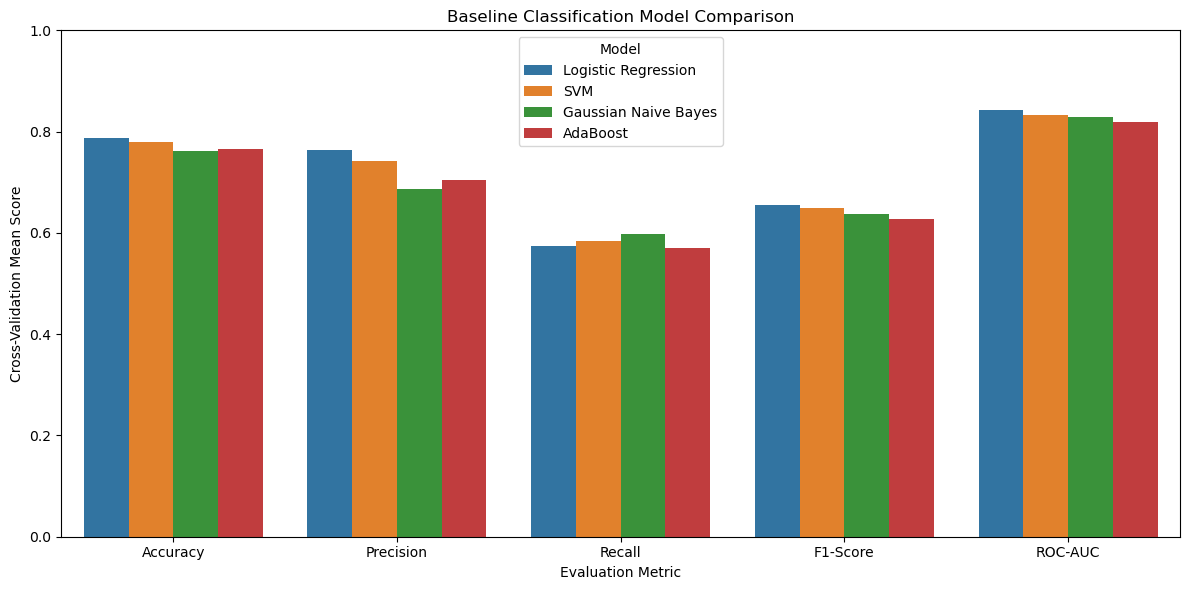

In [75]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Baseline Classification Model Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Cross-Validation Mean Score")
plt.ylim(0, 1)
plt.legend(title="Model")
plt.tight_layout()

plt.show()

#### Baseline Model Comparison Results

Four classification algorithms were evaluated using the same Stratified 5-Fold Cross-Validation strategy.

**Key Findings:**

- Logistic Regression achieved the highest Accuracy (0.788), Precision (0.764), F1-Score (0.655), and ROC-AUC (0.843).
- Gaussian Naive Bayes achieved the highest Recall (0.598).
- SVM produced results relatively close to Logistic Regression.
- AdaBoost achieved the lowest Recall (0.570), F1-Score (0.628), and ROC-AUC (0.818).

**Conclusion:**

Logistic Regression demonstrated the strongest overall baseline performance, while Gaussian Naive Bayes achieved the highest sensitivity.

However, all four models showed relatively limited Recall for identifying positive diabetes cases at their default classification thresholds.

Further experiments will focus on improving Recall while monitoring Precision, F1-Score, and ROC-AUC.

In [76]:
from sklearn.model_selection import GridSearchCV

param_grids = {
    "Logistic Regression": {
        "model__C": [0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },
    "SVM": {
        "model__C": [0.1, 1, 10],
        "model__gamma": ["scale", 0.1],
        "model__class_weight": [None, "balanced"]
    },
    "Gaussian Naive Bayes": {
        "model__var_smoothing": [1e-7, 1e-8, 1e-9, 1e-10]
    },
    "AdaBoost": {
        "model__n_estimators": [50, 100, 150],
        "model__learning_rate": [0.3, 1.0]
    }
}

In [77]:
tuned_models = {}
tuned_results = []

for name, pipeline in models.items():

    grid_search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring=scoring,
        refit="f1",
        cv=cv,
        n_jobs=-1
    )

    grid_search.fit(X_train_clean, y_train)

    tuned_models[name] = grid_search
    idx = grid_search.best_index_

    tuned_results.append({
        "Model": name,
        "Accuracy": grid_search.cv_results_["mean_test_accuracy"][idx],
        "Precision": grid_search.cv_results_["mean_test_precision"][idx],
        "Recall": grid_search.cv_results_["mean_test_recall"][idx],
        "F1-Score": grid_search.cv_results_["mean_test_f1"][idx],
        "ROC-AUC": grid_search.cv_results_["mean_test_roc_auc"][idx]
    })

    print(f"{name}: {grid_search.best_params_}")

tuned_df = pd.DataFrame(tuned_results)

display(tuned_df.round(3))

Logistic Regression: {'model__C': 0.1, 'model__class_weight': 'balanced'}
SVM: {'model__C': 1, 'model__class_weight': 'balanced', 'model__gamma': 'scale'}
Gaussian Naive Bayes: {'model__var_smoothing': 1e-07}
AdaBoost: {'model__learning_rate': 1.0, 'model__n_estimators': 150}


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.767,0.651,0.720,0.682,0.845
1,SVM,0.761,0.637,0.762,0.690,0.837
2,Gaussian Naive Bayes,0.762,0.686,0.598,0.637,0.828
3,AdaBoost,0.770,0.701,0.598,0.645,0.823


In [78]:
baseline_df = comparison_df.copy()
baseline_df["Version"] = "Baseline"

optimized_df = tuned_df.copy()
optimized_df["Version"] = "Tuned"

final_comparison = pd.concat(
    [baseline_df, optimized_df],
    ignore_index=True
)

final_comparison = final_comparison[
    ["Model", "Version", "Accuracy", "Precision",
     "Recall", "F1-Score", "ROC-AUC"]
]

display(final_comparison.round(3))

,Model,Version,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,Baseline,0.788,0.764,0.575,0.655,0.843
1,SVM,Baseline,0.780,0.742,0.584,0.648,0.833
2,Gaussian Naive Bayes,Baseline,0.762,0.686,0.598,0.637,0.828
3,AdaBoost,Baseline,0.765,0.704,0.570,0.628,0.818
4,Logistic Regression,Tuned,0.767,0.651,0.720,0.682,0.845
5,SVM,Tuned,0.761,0.637,0.762,0.690,0.837
6,Gaussian Naive Bayes,Tuned,0.762,0.686,0.598,0.637,0.828
7,AdaBoost,Tuned,0.770,0.701,0.598,0.645,0.823


In [79]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score
)

best_model_name = max(
    tuned_models,
    key=lambda name: tuned_models[name].best_score_
)

final_model = tuned_models[best_model_name].best_estimator_

y_pred = final_model.predict(X_test_clean)

if hasattr(final_model, "predict_proba"):
    y_scores = final_model.predict_proba(X_test_clean)[:, 1]
else:
    y_scores = final_model.decision_function(X_test_clean)

print("Selected Model:", best_model_name)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=3))

print("ROC-AUC:", round(roc_auc_score(y_test, y_scores), 3))

cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=["Actual Negative", "Actual Positive"],
    columns=["Predicted Negative", "Predicted Positive"]
)

display(cm)

Selected Model: SVM

Classification Report:
              precision    recall  f1-score   support

           0      0.830     0.730     0.777       100
           1      0.591     0.722     0.650        54

    accuracy                          0.727       154
   macro avg      0.710     0.726     0.713       154
weighted avg      0.746     0.727     0.732       154

ROC-AUC: 0.814


,Predicted Negative,Predicted Positive
Actual Negative,73,27
Actual Positive,15,39


## Final Results and Conclusion

Four classification algorithms were trained and compared:

- Logistic Regression
- Support Vector Machine (SVM)
- Gaussian Naive Bayes
- AdaBoost

Hyperparameter optimization was performed using GridSearchCV with Stratified 5-Fold Cross-Validation.

F1-Score was used as the optimization metric to balance Precision and Recall.

### Key Findings

- Logistic Regression achieved the highest baseline Accuracy and ROC-AUC.
- SVM achieved the highest F1-Score after hyperparameter optimization.
- Class weighting improved the detection of positive cases.
- Higher Recall came with a reduction in Precision.
- Hyperparameter selection was performed using training data only.

### Final Model

The optimized SVM model was selected based on cross-validation F1-Score.

**Test Set Performance:**

| Metric | Score |
|---|---:|
| Accuracy | 0.727 |
| Precision | 0.591 |
| Recall | 0.722 |
| F1-Score | 0.650 |
| ROC-AUC | 0.814 |

The final model correctly identified 39 out of 54 positive cases in the test set.

However, 15 positive cases were missed, and 27 negative cases were incorrectly classified as positive.

### Conclusion

Hyperparameter optimization improved the sensitivity of the selected classifier compared with its baseline performance.

However, the improvement in Recall involved a trade-off with Precision.

The results demonstrate the importance of selecting evaluation metrics according to the objective of the classification problem rather than relying solely on Accuracy.

The dataset is relatively small and represents a limited population, which restricts the generalizability of the findings. The models are intended for educational purposes and should not be used for clinical diagnosis.

Further improvements could include more advanced missing value imputation, decision threshold optimization, and evaluation on external datasets.